In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# Change for your data
root_path = Path("/data/smfish/20260311_bartelle_smFISH_cryo_48hr_male")

In [10]:
output_dir = root_path / "big_fish" / "results" / "all_tiles_2D"
matrix_path = output_dir / "cellxgene_matrix.csv"
# spots_path_bit5 = os.path.join(output_dir, "spots_bit_5.csv")
matrix = pd.read_csv(matrix_path, usecols= ['cell_id', 'Angpt1', 'Crmp1', 'Dcx', 'Hdac11', 'Itgam', 'Notch2',
       'Ptch1', 'Serpine1', 'Shh', 'Slc1a3', 'Tcf12', 'Tek', 'Tgfb1', 'Tgfbi', 'Aif1', 'Nnat'])
print(matrix.shape)
print(matrix.head())

(9709, 17)
   cell_id  Angpt1   Crmp1    Dcx  Hdac11  Itgam  Notch2  Ptch1  Serpine1  \
0        0    2748  119363  10559   78683  13164   10057  18360      8594   
1        1       0       1      0       0      0       0      0         0   
2        3       0       0      0       0      0       0      1         0   
3        5       0       1      0       0      0       0      3         0   
4        6       0      35      1      15      0       0      1         0   

    Shh  Slc1a3  Tcf12   Tek  Tgfb1  Tgfbi   Aif1   Nnat  
0  4103  103261   9700  8471  15820  13410  14236  13704  
1     0       1      0     0      0      0      0      0  
2     0       1      0     0      0      0      0      0  
3     0       9      0     0      0      0      0      3  
4     0       1      0     0      0      0      0      0  


In [7]:
matrix.columns

Index(['Angpt1', 'Crmp1', 'Dcx', 'Hdac11', 'Itgam', 'Notch2', 'Ptch1',
       'Serpine1', 'Shh', 'Slc1a3', 'Tcf12', 'Tek', 'Tgfb1', 'Tgfbi', 'Aif1',
       'Nnat'],
      dtype='str')

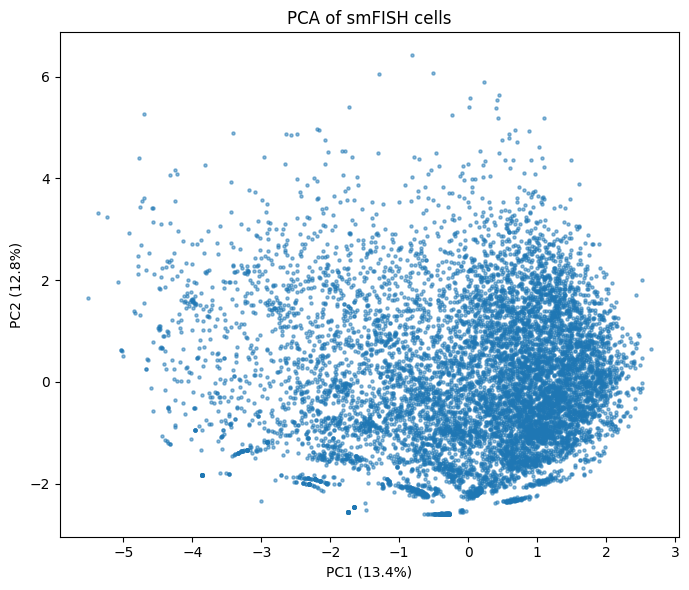

In [13]:
# Select gene counts and normalize each cell by its total counts
genes = matrix.columns.drop("cell_id")
counts = matrix[genes].astype(float)

library_size = counts.sum(axis=1).replace(0, 1)
log_counts = (counts.div(library_size, axis=0) * 1e4).apply(np.log1p)

# Standardize genes and run PCA
scaled_counts = StandardScaler().fit_transform(log_counts)
pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled_counts)

# Plot cells in PCA space
plt.figure(figsize=(7, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], s=5, alpha=0.5)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.title("PCA of smFISH cells")
plt.tight_layout()
plt.show()

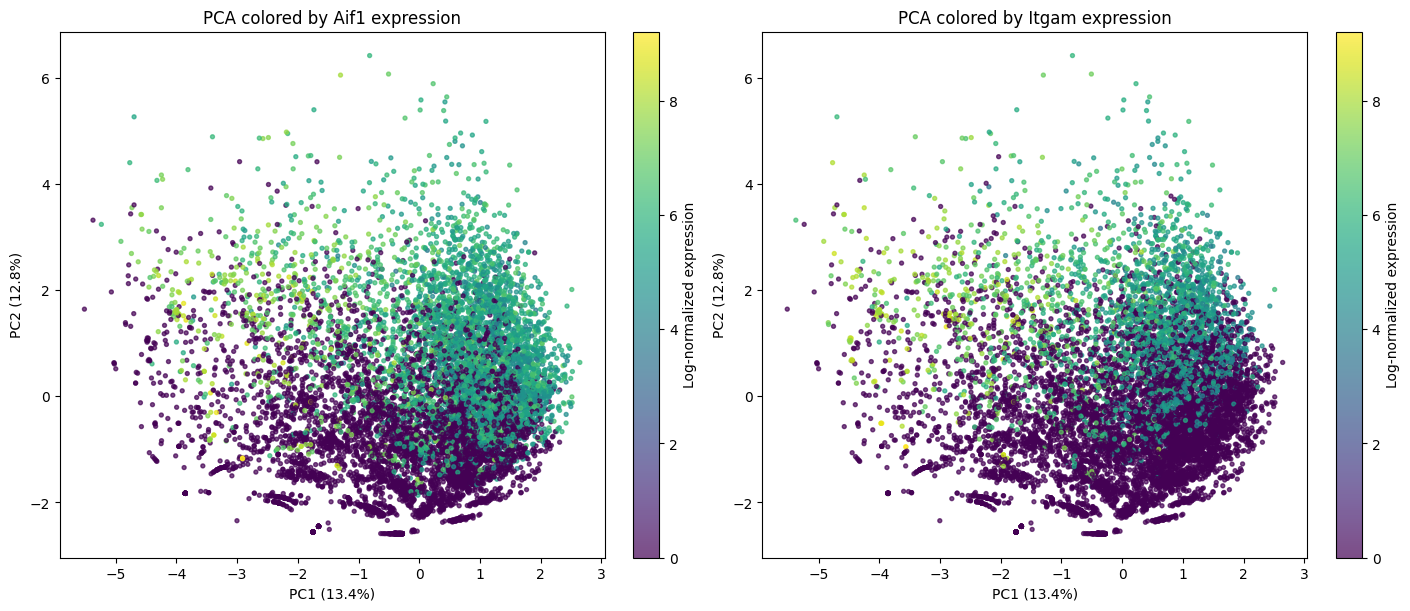

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

plt.show()

In [ ]:
# Normalize by library size without log transformation
normalized_counts = counts.div(library_size, axis=0) * 1e4

# Standardize genes and run PCA
scaled_counts = StandardScaler().fit_transform(normalized_counts)
pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    expression = normalized_counts[gene].to_numpy()
    positive = expression > 0

    # Plot all cells gray first
    ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        color="lightgray",
        s=8,
        alpha=0.7,
    )

    # Overlay cells with detected expression
    scatter = ax.scatter(
        pcs[positive, 0],
        pcs[positive, 1],
        c=expression[positive],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )

    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Library-size-normalized expression")

plt.show()